In [1]:
%load_ext autoreload
%autoreload 2
%matplotlib widget
%pwd

'/projectnb/batmanlab/mragoza/lung-project/notebooks/copdgene'

In [2]:
import sys, os

print(os.getpid())

os.environ['CUDA_LAUNCH_BLOCKING'] = '1'

def add_path(p: str):
    if p not in sys.path:
        sys.path.append(p)

add_path(os.environ['LP_ROOT'])
add_path(os.environ['PROJECT'])

import project

import torch
assert torch.cuda.is_available()

751587


# Gather examples

In [3]:
from pathlib import Path

#data_root = Path(os.environ['LP_ROOT']) / 'data' / 'COPDGene'
data_root = Path(os.environ['PRIVATE']) / 'data' / 'COPDGene'

subject_file = data_root / 'sample1000_2025-07-22.csv'
subject_list = project.fileio.load_subject_list(subject_file, key='sid', sep='\t')

bad_subjects = ['23686J', '24634V']
subject_list = [sid for sid in subject_list if sid not in bad_subjects][:1]

subject_list

Loading /restricted/projectnb/batmanlab/mragoza/data/COPDGene/sample1000_2025-07-22.csv


['16514P']

In [4]:
config = project.fileio.load_config('2026-09-15_config.yaml')

data_config = config['dataset']
data_config['subjects'] = subject_list
data_config['pipeline_tags']['mesh_generation'] = 'rad'
data_config['pipeline_tags']['field_interpolation'] = 'int'
data_config['pipeline_tags']['forward_simulation'] = 'LE'

project.utils.pprint(data_config)

Loading 2026-09-15_config.yaml
dict(len=6)
├── 'name':          'COPDGene'
├── 'root':          '/restricted/projectnb/batmanlab/mragoza/data/COPDGene'
├── 'subjects':      list(len=1)
|   └── 0: '16514P'
├── 'state_pairs':   list(len=1)
|   └── 0: list(len=2)
├── 'variant':       '2026-09-15'
└── 'pipeline_tags': dict(len=8)
    ├── 'image_resampling':    'iso'
    ├── 'image_segmentation':  'v3d'
    ├── 'image_registration':  'gil'
    ├── 'anatomical_regions':  'lung'
    ├── 'material_properties': 'bela'
    ├── 'mesh_generation':     'rad'
    ├── 'field_interpolation': 'int'
    └── 'forward_simulation':  'LE'


In [5]:
examples = project.get_examples(data_config)

Gathering examples...
1 total


# Training run

In [6]:
train_config = config['training']
project.utils.pprint(train_config)

dict(len=9)
├── 'seed':       1234
├── 'task':       dict(len=3)
|   ├── 'inputs':  list(len=1)
|   ├── 'targets': list(len=1)
|   └── 'losses':  dict(len=1)
├── 'split':      dict(len=3)
|   ├── 'key':        'category'
|   ├── 'test_ratio': 0.2
|   └── 'val_ratio':  0.1
├── 'transform':  dict(len=8)
|   ├── 'normalize':      True
|   ├── 'image_mean':     0.0
|   ├── 'image_std':      1.0
|   ├── 'apply_mask':     True
|   ├── 'do_augment':     True
|   ├── 'rand_rotate':    True
|   ├── 'rand_reflect':   True
|   └── 'rand_translate': 4.0
├── 'loader':     dict(len=3)
|   ├── 'batch_size':  1
|   ├── 'shuffle':     True
|   └── 'num_workers': 0
├── 'model':      dict(len=2)
|   ├── 'backbone': dict(len=11)
|   └── 'heads':    dict(len=1)
├── 'pde_solver': dict(len=5)
|   ├── 'type':          'warp'
|   ├── 'material_type': 'linear'
|   ├── 'g_vector':      list(len=3)
|   ├── 'relative_loss': True
|   └── 'tv_reg_weight': 1e-05
├── 'optimizer':  dict(len=2)
|   ├── 'type': 'AdamW'
|

In [7]:
train_config = {
    'seed': 1234,
    'task': {
        'inputs':  ['image'],
        'targets': ['E'],
        'losses':  {'E': 'sim'}
    },
    'split': {'method': 'random', 'test_ratio': 0, 'val_ratio': 0},
    'transform': {
        'normalize':  False,
        'apply_mask': False,
        'do_augment': False,
        'use_cache':  True
    },
    'loaders': {'batch_size': 1, 'shuffle': True},
    'model': {
        'backbone': {
            'type': 'UNet3D',
            'conv_channels': 8,
            'n_unet_levels': 2,
            'n_conv_units': 2
        },
        'heads': {
            'E': {
                'mode': 'log10', 'scale': 1.0, 'v_loc': 2e3, 'v_min': 0.0, 'v_max': 1e5
            }
        }
    },
    'optimizer': {'type': 'AdamW', 'lr': 1e-3},
    'pde_solver': {
        'type': 'warp',
        'material_type': 'linear',
        'g_vector': [0, -9.81, 0]
    },
    'boundary_condition': {'type': 'mesh_key', 'value': 'u_fwd'},
    'trainer': {'num_epochs': 100, 'save_interval': 10}
}

In [8]:
%ls checkpoints

checkpoint00000.pt  checkpoint00030.pt  checkpoint00060.pt  checkpoint00090.pt
checkpoint00010.pt  checkpoint00040.pt  checkpoint00070.pt  checkpoint00100.pt
checkpoint00020.pt  checkpoint00050.pt  checkpoint00080.pt


In [9]:
%rm -rf checkpoints

In [10]:
%autoreload
project.run_training(examples, train_config)

Splitting data examples
Train examples: 1
Test examples:  0
Val examples:   0


Validating training task
Inputs:  ['image']
Targets: ['E']
Losses:  {'E': 'sim'}
Building model architecture
MultiTaskModel(
  (backbone): UNet3D(
    (encoder): ConvBlock3D(
      (unit0): ConvUnit3D(
        (conv): Conv3d(1, 8, kernel_size=(3, 3, 3), stride=(1, 1, 1), padding=same, bias=False, padding_mode=replicate)
        (norm): GroupNorm(4, 8, eps=1e-05, affine=True)
        (act): LeakyReLU(negative_slope=0.1, inplace=True)
      )
      (unit1): ConvUnit3D(
        (conv): Conv3d(8, 8, kernel_size=(3, 3, 3), stride=(1, 1, 1), padding=same, bias=False, padding_mode=replicate)
        (norm): GroupNorm(4, 8, eps=1e-05, affine=True)
        (act): LeakyReLU(negative_slope=0.1, inplace=True)
      )
    )
    (unet): UNet3D(
      (encoder): ConvBlock3D(
        (unit0): ConvUnit3D(
          (conv): Conv3d(8, 16, kernel_size=(3, 3, 3), stride=(1, 1, 1), padding=same, bias=False, padding_mode=replicate)
          (norm): GroupNorm(4, 16, eps=1e-05, affine=True)
          (act): L

Training start
Saving checkpoints/checkpoint00000.pt
Loading /restricted/projectnb/batmanlab/mragoza/data/COPDGene/Processed/2026-09-15/16514P/images/16514P_EXP_iso.nii.gz
Loading /restricted/projectnb/batmanlab/mragoza/data/COPDGene/Processed/2026-09-15/16514P/masks/16514P_EXP_iso_v3d_domain.nii.gz
Loading /restricted/projectnb/batmanlab/mragoza/data/COPDGene/Processed/2026-09-15/16514P/meshes/16514P_EXP_iso_v3d_gil_INSP_lung_rad_bela_int_LE.xdmf
Loading /restricted/projectnb/batmanlab/mragoza/data/COPDGene/Processed/2026-09-15/16514P/fields/16514P_EXP_iso_v3d_bela_label.nii.gz
Loading /restricted/projectnb/batmanlab/mragoza/data/COPDGene/Processed/2026-09-15/16514P/masks/16514P_EXP_iso_v3d_lung.nii.gz
[Epoch 0 | Train batch 0] loss = 0.00171936  peak alloc = 33.28 GiB  peak resvd = 35.63 GiB
Saving outputs/training/metrics.tmp
[Epoch 1 | Train batch 0] loss = 0.00140384  peak alloc = 26.86 GiB  peak resvd = 37.92 GiB
[Epoch 2 | Train batch 0] loss = 0.000332572  peak alloc = 26.86 Gi

In [11]:
import pandas as pd
df = pd.read_csv('outputs/training/metrics.csv')
df

,epoch,phase,batch,loss,grad_norm,group,label,num_voxels,E_vox.mean,E_vox.std,...,u_cell.mean,u_cell.std,u_cell.rms,u_cell.mae,u_cell.mre,u_cell.rmse,u_cell.nrmse,res_cell.mean,res_cell.std,res_cell.rms
0,0,train,0,0.001719,0.124507,NaN,NaN,2144006,732.148361,332.345618,...,0.012276,0.005215,0.013338,0.000854,0.066973,0.001042,0.075971,0.001251,0.002262,0.002585
1,1,train,0,0.001404,0.072039,NaN,NaN,2144006,1050.004675,296.066763,...,0.013207,0.005018,0.014128,0.000742,0.058213,0.000946,0.069012,0.001819,0.003299,0.003767
2,2,train,0,0.000333,0.005940,NaN,NaN,2144006,1082.986748,210.055912,...,0.012821,0.005139,0.013813,0.000372,0.029207,0.000447,0.032581,0.001935,0.003457,0.003962
3,3,train,0,0.000347,0.006065,NaN,NaN,2144006,1095.591859,181.727163,...,0.012752,0.005164,0.013758,0.000388,0.030465,0.000459,0.033501,0.001966,0.003510,0.004024
4,4,train,0,0.000345,0.005623,NaN,NaN,2144006,1113.377933,167.495550,...,0.012734,0.005171,0.013744,0.000387,0.030383,0.000459,0.033491,0.002001,0.003571,0.004093
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,95,train,0,0.000047,0.000076,NaN,NaN,2144006,1978.989270,307.055440,...,0.012760,0.005053,0.013724,0.000112,0.008773,0.000144,0.010512,0.003472,0.006223,0.007126
96,96,train,0,0.000046,0.000073,NaN,NaN,2144006,1982.750461,307.427476,...,0.012760,0.005053,0.013724,0.000111,0.008720,0.000144,0.010464,0.003479,0.006235,0.007139
97,97,train,0,0.000046,0.000069,NaN,NaN,2144006,1987.177922,307.627966,...,0.012760,0.005053,0.013724,0.000111,0.008669,0.000143,0.010415,0.003487,0.006249,0.007156
98,98,train,0,0.000045,0.000064,NaN,NaN,2144006,1992.409267,307.791546,...,0.012760,0.005053,0.013724,0.000110,0.008621,0.000142,0.010368,0.003496,0.006266,0.007175


/scratch/8130850.1.ece-long/ipykernel_748338/2747411774.py:8: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  fig, axes = plt.subplots(1, n_axes, figsize=(3*n_axes, 4), squeeze=False)


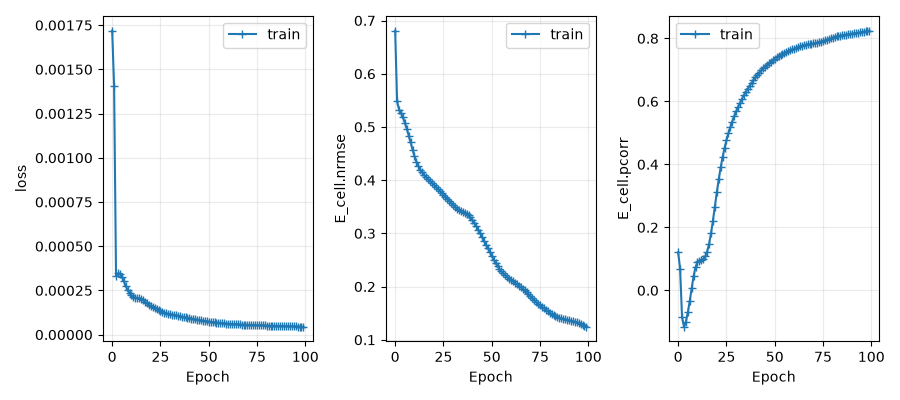

In [35]:
import matplotlib.pyplot as plt

def plot_training(df, metrics=['loss', 'E_cell.nrmse', 'E_cell.pcorr']):
    n_axes = len(metrics)
    
    curves = df.groupby(['epoch', 'phase'])[metrics].mean()

    fig, axes = plt.subplots(1, n_axes, figsize=(3*n_axes, 4), squeeze=False)
    axes = axes.ravel()

    for ax, metric in zip(axes, metrics):
        values = curves[metric].unstack('phase').sort_index()

        for phase in ['train', 'val', 'test']:
            if phase in values:
                series = values[phase].dropna()
                ax.plot(series.index, series, marker='+', label=phase)
        
        ax.set(xlabel='Epoch', ylabel=metric)
        ax.legend()
        ax.grid(alpha=0.25)

    fig.tight_layout()
    return fig

fig = plot_training(df)
plt.pause(3.0)

In [9]:
ex = examples[0]

nifti = project.fileio.load_nibabel(ex.paths['input_image'])
image = nifti.get_fdata()
affine = nifti.affine

mask = project.fileio.load_nibabel(ex.paths['anatomical_map']).get_fdata() > 0

E_true = project.fileio.load_nibabel(ex.paths['material_dir'] / 'youngs_modulus.nii.gz').get_fdata()

Loading /restricted/projectnb/batmanlab/mragoza/data/COPDGene/Processed/2026-09-15/16514P/images/16514P_EXP_iso.nii.gz
Loading /restricted/projectnb/batmanlab/mragoza/data/COPDGene/Processed/2026-09-15/16514P/masks/16514P_EXP_iso_v3d_lung.nii.gz
Loading /restricted/projectnb/batmanlab/mragoza/data/COPDGene/Processed/2026-09-15/16514P/fields/16514P_EXP_iso_v3d_bela/youngs_modulus.nii.gz


In [10]:
import project.training
trainer = project.training.get_trainer(examples, train_config)

Splitting data examples
Train examples: 1
Test examples:  0
Val examples:   0


Validating training task
Inputs:  ['image']
Targets: ['E']
Losses:  {'E': 'sim'}
Building model architecture
MultiTaskModel(
  (backbone): UNet3D(
    (encoder): ConvBlock3D(
      (unit0): ConvUnit3D(
        (conv): Conv3d(1, 8, kernel_size=(3, 3, 3), stride=(1, 1, 1), padding=same, bias=False, padding_mode=replicate)
        (norm): GroupNorm(4, 8, eps=1e-05, affine=True)
        (act): LeakyReLU(negative_slope=0.1, inplace=True)
      )
      (unit1): ConvUnit3D(
        (conv): Conv3d(8, 8, kernel_size=(3, 3, 3), stride=(1, 1, 1), padding=same, bias=False, padding_mode=replicate)
        (norm): GroupNorm(4, 8, eps=1e-05, affine=True)
        (act): LeakyReLU(negative_slope=0.1, inplace=True)
      )
    )
    (unet): UNet3D(
      (encoder): ConvBlock3D(
        (unit0): ConvUnit3D(
          (conv): Conv3d(8, 16, kernel_size=(3, 3, 3), stride=(1, 1, 1), padding=same, bias=False, padding_mode=replicate)
          (norm): GroupNorm(4, 16, eps=1e-05, affine=True)
          (act): L

In [11]:
batch = next(iter(trainer.train_loader))
project.utils.pprint(batch)

Loading /restricted/projectnb/batmanlab/mragoza/data/COPDGene/Processed/2026-09-15/16514P/images/16514P_EXP_iso.nii.gz
Loading /restricted/projectnb/batmanlab/mragoza/data/COPDGene/Processed/2026-09-15/16514P/masks/16514P_EXP_iso_v3d_domain.nii.gz
Loading /restricted/projectnb/batmanlab/mragoza/data/COPDGene/Processed/2026-09-15/16514P/meshes/16514P_EXP_iso_v3d_gil_INSP_lung_rad_bela_int_LE.xdmf
Loading /restricted/projectnb/batmanlab/mragoza/data/COPDGene/Processed/2026-09-15/16514P/fields/16514P_EXP_iso_v3d_bela_label.nii.gz
Loading /restricted/projectnb/batmanlab/mragoza/data/COPDGene/Processed/2026-09-15/16514P/masks/16514P_EXP_iso_v3d_lung.nii.gz
dict(len=7)
├── 'example':  list(len=1)
|   └── 0: Example()
├── 'affine':   Tensor(shape=torch.Size([1, 4, 4]), dtype=torch.float32, device=cpu)
|   └── 0: Tensor(shape=torch.Size([4, 4]), dtype=torch.float32, device=cpu)
├── 'image':    Tensor(shape=torch.Size([1, 1, 368, 368, 268]), dtype=torch.float32, device=cpu)
|   └── 0: Tensor(sh

In [12]:
outputs = trainer.run_batch(batch, eval_mode=True)[1]
project.utils.pprint(outputs)

dict(len=5)
├── 'batch':   dict(len=7)
|   ├── 'example':  list(len=1)
|   ├── 'affine':   Tensor(shape=torch.Size([1, 4, 4]), dtype=torch.float32, device=cpu)
|   ├── 'image':    Tensor(shape=torch.Size([1, 1, 368, 368, 268]), dtype=torch.float32, device=cpu)
|   ├── 'mask':     Tensor(shape=torch.Size([1, 1, 368, 368, 268]), dtype=torch.bool, device=cpu)
|   ├── 'mesh':     list(len=1)
|   ├── 'material': Tensor(shape=torch.Size([1, 1, 368, 368, 268]), dtype=torch.int64, device=cpu)
|   └── 'anatomy':  Tensor(shape=torch.Size([1, 1, 368, 368, 268]), dtype=torch.int64, device=cpu)
├── 'preds':   dict(len=1)
|   └── 'E': Tensor(shape=torch.Size([1, 1, 368, 368, 268]), dtype=torch.float32, device=cuda:0)
├── 'sims':    list(len=1)
|   └── 0: dict(len=6)
├── 'loss':    torch.float32(4.4862e-05)
└── 'metrics': list(len=1)
    └── 0: dict(len=26)


In [17]:
E_pred = outputs['preds']['E'].detach().cpu().numpy()[0,0]
E_true.shape, E_pred.shape

((368, 368, 268), (368, 368, 268))

In [23]:
import project.visual.matplotlib as mpl_viz
import matplotlib.pyplot as plt

img_kws = dict(cmap='gray', vmin=-1000, vmax=-500)
E_t_kws = dict(cmap='jet', vmin=0, vmax=1e4)
E_p_kws = dict(cmap='jet', vmin=0, vmax=1e4)
err_kws = dict(cmap='seismic', vmin=-1, vmax=1)

grid_kws = dict(cbar_width=0.2, padding=(0.5, 0.65, 0.35, 0.3))

In [30]:
import numpy as np

img_m = image * mask
E_t_m = E_true * mask
E_p_m = E_pred * mask

err_m = np.log10(np.maximum(E_pred / E_true, 1e-12)) * mask

z = E_true.shape[-1] // 2
z

134

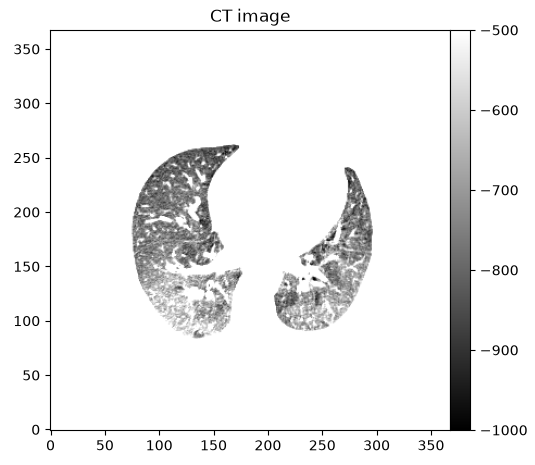

In [31]:
fig, ax, cax = mpl_viz.subplot_grid(1, 1, 4, 4, **grid_kws)
ax[0,0].set_title('CT image')
im = ax[0,0].imshow(img_m[:,:,z].T, origin='lower', **img_kws)
plt.colorbar(im, cax)

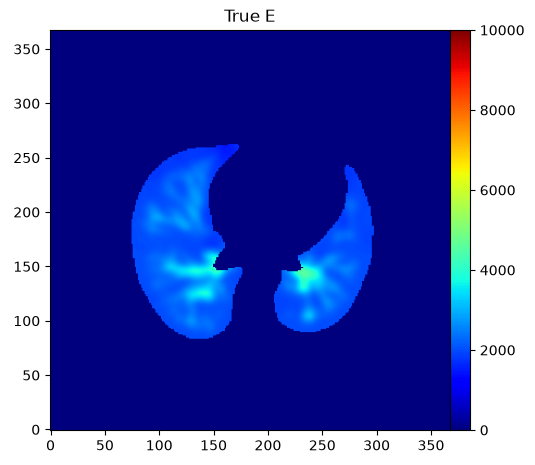

In [32]:
fig, ax, cax = mpl_viz.subplot_grid(1, 1, 4, 4, **grid_kws)
ax[0,0].set_title('True E')
im = ax[0,0].imshow(E_t_m[:,:,z].T, origin='lower', **E_t_kws)
plt.colorbar(im, cax)

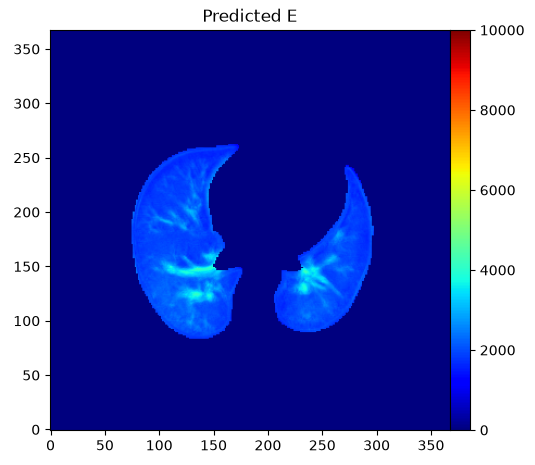

In [33]:
fig, ax, cax = mpl_viz.subplot_grid(1, 1, 4, 4, **grid_kws)
ax[0,0].set_title('Predicted E')
im = ax[0,0].imshow(E_p_m[:,:,z].T, origin='lower', **E_p_kws)
plt.colorbar(im, cax)

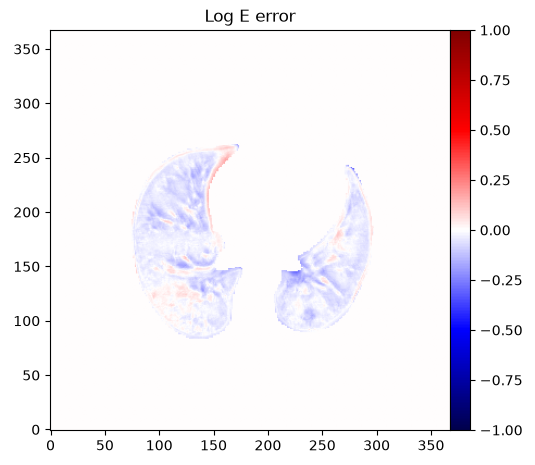

In [34]:
fig, ax, cax = mpl_viz.subplot_grid(1, 1, 4, 4, **grid_kws)
ax[0,0].set_title('Log E error')
im = ax[0,0].imshow(err_m[:,:,z].T, origin='lower', **err_kws)
plt.colorbar(im, cax)